# Pipeline dos encodings

In [1]:
import os, sys, subprocess
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.width', 220, 'display.max_columns', 30)
R = Path('reports/a2_encoding')
SOURCE = 'small'
rng = np.random.default_rng(0)

## Backend

In [2]:
from qiskit import QuantumCircuit
from quantum.encoding.backends import N_QUBITS, exact_state, make_noise_model, noisy_density_matrix

qc = QuantumCircuit(2); qc.h(0); qc.cx(0, 1)
psi = exact_state(qc)
print('qubits padrão:', N_QUBITS, '| Bell exato:', np.round(psi, 3))
rho = noisy_density_matrix(qc, make_noise_model(p1=1e-3, p2=1e-2, p_readout=0))
print('fidelidade do Bell sob ruído de portas:', round(float(np.real(psi.conj() @ rho @ psi)), 4))

qubits padrão: 8 | Bell exato: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
fidelidade do Bell sob ruído de portas: 0.992


## Dados 

In [3]:
from quantum.encoding import data
a = data.load_angles(SOURCE, 'medium', 'val', k=8)
print('angles  X', a.X.shape, 'min/max', a.X.min().round(2), a.X.max().round(2), '| saturação média', round(float(a.below.mean() + a.above.mean()), 3))
v = data.load_amplitudes(SOURCE, 'medium', 'val')
print('amplitude V', v.V.shape, '| unidades informativas', v.n_features, '| unidades mortas na origem', int(data.dead_units(SOURCE).sum()))
sat = pd.read_csv(R / 'saturation.csv')
display(sat[sat.split == 'test'].pivot_table(index=['source', 'k'], columns='domain', values='saturated').round(3))

angles  X (281, 8) min/max 0.0 1.0 | saturação média 0.042
amplitude V (281, 256) | unidades informativas 84 | unidades mortas na origem 19


domain       big  medium  small
source k                       
big    8   0.013   0.018  0.027
       16  0.012   0.024  0.020
medium 8   0.009   0.023  0.022
       16  0.009   0.021  0.023
small  8   0.031   0.040  0.018
       16  0.031   0.036  0.014

## Encoders .

--- angle (4 qubits)


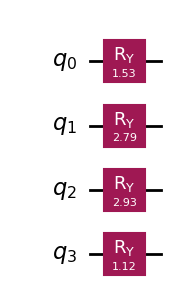

--- dense (4 qubits)


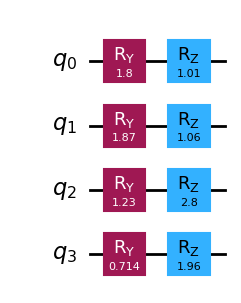

--- zz (4 qubits)


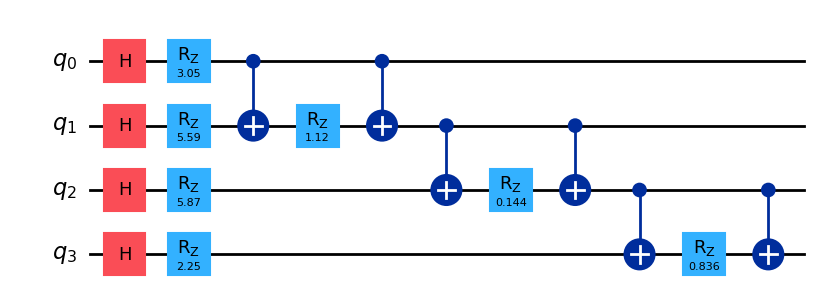

,encoder,config,qubits,features,depth,cx,one_qubit
0,angle,,8,8,1,0,8
1,dense,,8,16,2,0,16
2,zz,"entanglement=linear,reps=1",8,8,23,14,23
3,zz,"entanglement=circular,reps=2",8,8,52,32,48
4,amplitude,,8,256,1487,247,1275


In [14]:
import matplotlib.pyplot as plt
from quantum.encoding.encoders import ENCODERS, build_circuit, resources

x4 = rng.random(4)

for name, cfg, x in [
    ('angle', {}, x4),
    ('dense', {}, rng.random(8)),
    ('zz', {'reps': 1, 'entanglement': 'linear'}, x4),
]:
    print(f'--- {name} (4 qubits)')
    fig = build_circuit(name, x, n_qubits=4, **cfg).draw('mpl')
    display(fig) 

cost = pd.DataFrame([
    resources('angle'),
    resources('dense'),
    resources('zz', reps=1, entanglement='linear'),
    resources('zz', reps=2, entanglement='circular'),
    resources('amplitude')
])

display(cost[['encoder', 'config', 'qubits', 'features', 'depth', 'cx', 'one_qubit']])

## Simulação em lote 

In [5]:
from quantum.encoding.encoders import load_inputs
from quantum.encoding.simulate import states, kernel, probabilities, expectations
x, y = load_inputs('zz', SOURCE, SOURCE, 'val', 'penultimate', 8)
cfg = {'reps': 1, 'entanglement': 'linear'}
S = states('zz', x, **cfg)
ref = exact_state(build_circuit('zz', x[0], **cfg))
print('estados', S.shape, '| fidelidade NumPy vs Qiskit (amostra 0):', round(abs(np.vdot(ref, S[0])) ** 2, 6))
K = kernel(S); off = ~np.eye(len(K), dtype=bool)
print('kernel', K.shape, '| média fora da diagonal', K[off].mean().round(3), '| desvio', K[off].std().round(3))
z, zz = expectations(probabilities(S))
print('<Z>', z.shape, '| <ZZ> (28 pares)', zz.shape)

estados (92, 256) | fidelidade NumPy vs Qiskit (amostra 0): 1.0
kernel (92, 92) | média fora da diagonal 0.036 | desvio 0.118
<Z> (92, 8) | <ZZ> (28 pares) (92, 28)


## Propriedades do encoding

In [6]:
from quantum.encoding.properties import properties, CONFIGS
rows = [properties(n, c, SOURCE, SOURCE) for n, c in CONFIGS]
cols = ['encoder', 'sat', 'k_mean', 'k_std', 'snr_1024', 'k_gap', 'kta', 'kta_null95', 'eff_rank', 'entangle']
display(pd.DataFrame(rows)[cols].round(3))

,encoder,sat,k_mean,k_std,snr_1024,k_gap,kta,kta_null95,eff_rank,entangle
0,angle,0.014,0.521,0.294,9.394,0.078,0.191,0.053,5.018,-0.000
1,dense,0.011,0.217,0.174,5.583,0.036,0.164,0.078,27.644,0.000
2,zz_r1_linear,0.014,0.036,0.118,3.762,0.020,0.121,0.090,55.245,0.353
3,zz_r2_circular,0.014,0.018,0.072,2.312,0.011,0.118,0.102,73.469,0.335
4,amplitude,NaN,0.617,0.294,9.409,-0.004,0.039,0.062,4.133,0.393


##  Avaliação 

In [7]:
from quantum.encoding.evaluate import evaluate_config
rows = evaluate_config('angle', {}, SOURCE, 'penultimate', 8)
display(pd.DataFrame(rows)[['reader', 'source', 'target', 'params', 'val_auc', 'test_auc', 'ci_low', 'ci_high', 'test_pr_auc']].round(3))

,reader,source,target,params,val_auc,test_auc,ci_low,ci_high,test_pr_auc
0,kernel,small,small,C=1.0,0.795,0.754,0.643,0.855,0.585
1,kernel,small,medium,C=1.0,0.795,0.618,0.537,0.694,0.497
2,kernel,small,big,C=1.0,0.795,0.673,0.615,0.726,0.799
3,measure,small,small,C=0.1,0.796,0.768,0.663,0.860,0.601
4,measure,small,medium,C=0.1,0.796,0.628,0.551,0.703,0.513
5,measure,small,big,C=0.1,0.796,0.682,0.624,0.735,0.808


## Grade 

In [8]:
from quantum.encoding.grid import POINTS
print(len(POINTS), 'pontos |', sum(1 for p in POINTS if p.layer == 'penultimate'), 'na penúltima')
display(pd.DataFrame({'qubits': {p.id: p.config.get('n_qubits', 8) for p in POINTS}}).T)
ideal = pd.read_csv(R / 'eval_grid.csv')
display(ideal.groupby(['point', 'reader'])[['val_auc', 'test_auc']].mean().unstack('reader').round(3).head(8))

17 pontos | 9 na penúltima


,penultimate/angle/k4,penultimate/angle/k8,penultimate/zz_r1_linear/k4,penultimate/zz_r2_circular/k4,penultimate/zz_r1_linear/k8,penultimate/zz_r2_circular/k8,penultimate/dense/k8,penultimate/dense/k16,feature_maps/angle/k4,feature_maps/angle/k8,feature_maps/zz_r1_linear/k4,feature_maps/zz_r2_circular/k4,feature_maps/zz_r1_linear/k8,feature_maps/zz_r2_circular/k8,feature_maps/dense/k8,feature_maps/dense/k16,penultimate/amplitude/k84
qubits,4,8,4,4,8,8,4,8,4,8,4,4,8,8,4,8,8


val_auc         test_auc        
reader                          kernel measure   kernel measure
point                                                          
feature_maps/angle/k4            0.748   0.715    0.676   0.687
feature_maps/angle/k8            0.800   0.780    0.693   0.698
feature_maps/dense/k16           0.820   0.722    0.730   0.661
feature_maps/dense/k8            0.787   0.711    0.707   0.650
feature_maps/zz_r1_linear/k4     0.665   0.455    0.594   0.503
feature_maps/zz_r1_linear/k8     0.693   0.507    0.614   0.487
feature_maps/zz_r2_circular/k4   0.620   0.526    0.548   0.545
feature_maps/zz_r2_circular/k8   0.633   0.525    0.588   0.548

## Baselines na mesma entrada 

In [9]:
from quantum.encoding import baselines
rows = baselines.input_reader('pc8', SOURCE, 'rbf', 'penultimate') + baselines.input_reader('pc8', SOURCE, 'logreg', 'penultimate')
rows += baselines.head_rows(SOURCE, 'penultimate') + baselines.lenet_rows(SOURCE)
b = pd.DataFrame(rows)
display(b.pivot_table(index='reader', columns='target', values='test_auc', sort=False).round(3))

target,small,medium,big
reader,,,
rbf,0.783,0.650,0.679
logreg,0.775,0.655,0.687
head41_mean,0.749,0.642,0.683
head41_valbest,0.773,0.628,0.676
lenet_final,0.780,0.685,0.682
lenet_ref20,0.773,0.679,0.675


## Shots e ruído 

In [10]:
from quantum.encoding.noise_eval import shot_kernel, sample_probabilities, SHOTS
from quantum.encoding.simulate import noisy_probabilities_batch
xa, _ = load_inputs('angle', SOURCE, SOURCE, 'val', 'penultimate', 8); xa = xa[:20]
Sa = states('angle', xa); Ka = kernel(Sa)
Kh = shot_kernel(Sa, None, SHOTS, np.random.default_rng(1)); off = ~np.eye(20, dtype=bool)
print(f'kernel com {SHOTS} shots: erro médio {np.abs(Kh - Ka)[off].mean():.4f}')
P0 = probabilities(Sa)
tv = lambda p, q: 0.5 * np.abs(p - q).sum(1).mean()
Ps = sample_probabilities(P0, SHOTS, np.random.default_rng(2))
Pn = noisy_probabilities_batch('angle', xa, make_noise_model(), SHOTS)
print('distância de variação total vs ideal -> só shots:', round(tv(Ps, P0), 3), '| shots + ruído Aer:', round(tv(Pn, P0), 3))
fid = pd.read_csv(R / 'noise_fidelity.csv')
display(fid.round(3))

kernel com 1024 shots: erro médio 0.0103
distância de variação total vs ideal -> só shots: 0.123 | shots + ruído Aer: 0.127


,point,fidelity,fidelity_min,qubits,depth,cx
0,penultimate/angle/k4,0.998,0.998,4,1,0
1,penultimate/angle/k8,0.996,0.996,8,1,0
2,penultimate/zz_r1_linear/k4,0.948,0.946,4,11,6
3,penultimate/zz_r2_circular/k4,0.863,0.854,4,28,16
4,penultimate/zz_r1_linear/k8,0.883,0.879,8,23,14
5,penultimate/zz_r2_circular/k8,0.746,0.736,8,52,32
6,penultimate/dense/k8,0.996,0.996,4,2,0
7,penultimate/dense/k16,0.992,0.992,8,2,0
8,penultimate/amplitude/k84,0.062,0.060,8,1487,247


## Decisão

In [11]:
from quantum.encoding import decision
ranking = decision.build_ranking(ideal, pd.read_csv(R / 'eval_grid_baselines.csv'), pd.read_csv(R / 'noise_shots.csv'), fid)
print(len(ranking), 'pontos |', int(ranking.eligible.sum()), 'elegíveis')
display(ranking[['rank', 'point', 'best_reader', 'val_auc', 'val_probe', 'shot_drop', 'fidelity', 'depth', 'cx', 'qubits', 'eligible']].head(6).round(3))
print('finalistas:', list(decision.select_finalists(ranking).point))

17 pontos | 8 elegíveis


,rank,point,best_reader,val_auc,val_probe,shot_drop,fidelity,depth,cx,qubits,eligible
0,1,penultimate/angle/k4,kernel,0.820,0.820,-0.002,0.998,1,0,4,True
1,2,penultimate/angle/k8,measure,0.819,0.822,-0.005,0.996,1,0,8,True
2,3,penultimate/dense/k8,measure,0.819,0.822,0.003,0.996,2,0,4,True
3,4,penultimate/dense/k16,kernel,0.821,0.823,0.003,0.992,2,0,8,True
4,5,feature_maps/dense/k16,kernel,0.820,0.775,0.012,0.992,2,0,8,True
5,6,feature_maps/angle/k8,kernel,0.800,0.778,0.007,0.996,1,0,8,True


finalistas: ['penultimate/angle/k4', 'penultimate/angle/k8']
